In [1]:
library(dplyr)
## visualization
library(ggplot2)
library(ggplot2)
library(gridExtra)
library(dplyr)
library(ggplot2)
library(cowplot)


Attaching package: ‘dplyr’


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union



Attaching package: ‘gridExtra’


The following object is masked from ‘package:dplyr’:

    combine




In [2]:
setwd("/home/liuxuan/metadata/PRJNA395436")
initial_meta<-read.csv("SraRunTable.csv",header = T)
head(initial_meta)
colnames(initial_meta)

,Run,AGE,Assay.Type,AvgSpotLen,Bases,BIOMATERIAL_PROVIDER,BioProject,BioSample,BioSampleModel,Bytes,⋯,Organism,Platform,ReleaseDate,Sample.Name,sample_type,sex,SRA.Study,tissue,create_date,version
,<chr>,<int>,<chr>,<int>,<int>,<chr>,<chr>,<chr>,<chr>,<int>,⋯,<chr>,<chr>,<chr>,<chr>,<int>,<chr>,<chr>,<chr>,<chr>,<int>
1,SRR5868140,26,MRE-Seq,298,37079218,Shanghai Personalbio company,PRJNA395436,SAMN07405848,Human,28017084,⋯,human oral metagenome,ILLUMINA,2018-07-26T00:00:00Z,AP1_R2,19,female,SRP113577,supragingival plaque,2017-09-21T15:28:00Z,1
2,SRR5868143,26,MRE-Seq,296,36860700,Shanghai Personalbio company,PRJNA395436,SAMN07405830,Human,21398262,⋯,human oral metagenome,ILLUMINA,2018-07-26T00:00:00Z,AP1_R1,1,female,SRP113577,supragingival plaque,2017-07-30T01:29:00Z,1
3,SRR5922127,25,RNA-Seq,495,98821136,Shanghai Personalbio company,PRJNA395436,SAMN07406051,Human,61853448,⋯,human oral metagenome,ILLUMINA,2017-08-10T00:00:00Z,FS3_R1,222,female,SRP113577,saliva,2017-08-10T15:33:00Z,1
4,SRR5922130,30,RNA-Seq,594,55274727,Shanghai Personalbio company,PRJNA395436,SAMN07405950,Human,35163538,⋯,human oral metagenome,ILLUMINA,2017-08-10T00:00:00Z,MP4_R1,121,female,SRP113577,supragingival plaque,2017-08-10T15:34:00Z,1
5,SRR5922131,25,RNA-Seq,594,36969136,Shanghai Personalbio company,PRJNA395436,SAMN07405916,Human,23787879,⋯,human oral metagenome,ILLUMINA,2017-08-10T00:00:00Z,OP3_R1,87,female,SRP113577,supragingival plaque,2017-08-10T15:34:00Z,1
6,SRR5922133,30,RNA-Seq,594,73365848,Shanghai Personalbio company,PRJNA395436,SAMN07405940,Human,46114197,⋯,human oral metagenome,ILLUMINA,2017-08-10T00:00:00Z,CP4_R1,111,female,SRP113577,supragingival plaque,2017-08-10T15:33:00Z,1


[1] "Run"                  "AGE"                  "Assay.Type"          
 [4] "AvgSpotLen"           "Bases"                "BIOMATERIAL_PROVIDER"
 [7] "BioProject"           "BioSample"            "BioSampleModel"      
[10] "Bytes"                "Center.Name"          "Consent"             
[13] "DATASTORE.filetype"   "DATASTORE.provider"   "DATASTORE.region"    
[16] "Experiment"           "Instrument"           "isolate"             
[19] "Library.Name"         "LibraryLayout"        "LibrarySelection"    
[22] "LibrarySource"        "Organism"             "Platform"            
[25] "ReleaseDate"          "Sample.Name"          "sample_type"         
[28] "sex"                  "SRA.Study"            "tissue"              
[31] "create_date"          "version"

In [3]:
uniform_meta <- data.frame(
    BioProject = initial_meta$BioProject,
    Run = initial_meta$Run,
    sample_name = initial_meta$'Sample.Name',
    Age = NA,
    BMI = NA,
    Sex = initial_meta$sex,
    Region = "V4-V5",
    Platform = initial_meta$Platform,
    Country = 'China',
    Site = initial_meta$tissue,
    public_time = initial_meta$ReleaseDate,
    PCR_primers = 'F: GTGCCAGCMGCCGCGGTAA; R: CCGTCAATTYYTTTRAGTTT',
    title = 'Pregnancy-Related Ecological Shifts of Salivary Microbiota and its Association with Salivary Sex Hormones',
    Disease_study = "NO",
    Status = NA,
    matched_samples = 'NO'
)
print(length(unique(uniform_meta$Run)))

print(length(unique(uniform_meta$sample_name)))

[1] 143
[1] 142


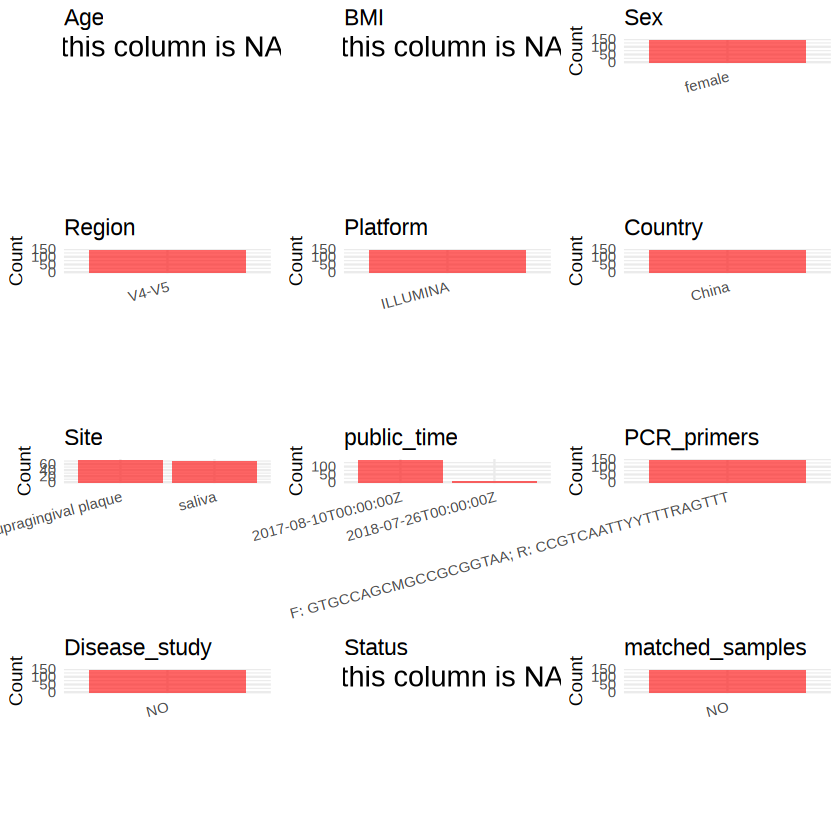

In [4]:
plot_data <- uniform_meta %>%
  select(-BioProject, -Run, -sample_name, -title)
create_simple_plots <- function(data) {
  plots <- list()
  
  for (col in colnames(data)) {
    # Check if the column is all NA
    if (all(is.na(data[[col]]))) {
      # Create an empty plot with text indicating all NA
      p <- ggplot() +
        annotate("text", x = 0.5, y = 0.5, label = "this column is NA", size = 6) +
        labs(title = col) +
        theme_void()
    } else if (is.numeric(data[[col]])) {
      # Numeric variable: histogram
      p <- ggplot(data, aes(x = .data[[col]])) +
        geom_histogram(fill = "blue", alpha = 0.6, bins = 20, na.rm = TRUE) +
        labs(title = col) +
        theme_minimal()
    } else {
      # Categorical variable: bar plot (remove NA values)
      count_data <- as.data.frame(table(data[[col]], useNA = "ifany"))
      p <- ggplot(count_data, aes(x = reorder(Var1, -Freq), y = Freq)) +
        geom_col(fill = "red", alpha = 0.6) +
        labs(title = col, x = NULL, y = "Count") +
        theme_minimal() +
        theme(axis.text.x = element_text(angle = 15, hjust = 1))
    }
    plots[[col]] <- p
  }
  
  return(plots)
}
plots <- create_simple_plots(plot_data)
p<-plot_grid(plots$Age, 
          plots$BMI, 
          plots$Sex, 
          plots$Region, 
          plots$Platform, 
          plots$Country, 
          plots$Site,
          plots$public_time, 
          plots$PCR_primers,
          plots$Disease_study,
          plots$Status,
          plots$matched_samples,# add 
          ncol = 3, align = "hv", axis = "lb")
p

In [5]:
## uniform the column order
uniform_meta <- uniform_meta[, c("BioProject", "Run", "sample_name", "Age", "BMI", "Sex", "Region", "Platform", "Country", "Site", "public_time", "PCR_primers", "title", "Disease_study", "Status")]
write.csv(uniform_meta, file = "/home/liuxuan/metadata/PRJNA395436/metadata.csv", quote = F)